In [1]:
from pathlib import Path
import os, json, random, subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau
import cv2

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay)

print(f"Tensorflow:{tf.__version__}, OpenCV:{cv2.__version__}")
print(f"GPU:{tf.config.list_physical_devices("GPU")}")

Tensorflow:2.21.0, OpenCV:5.0.0
GPU:[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SEED = 42
IMG_SIZE = 224
DEFECT_CUTOFF = 0.5
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-3

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(parents=True,exist_ok=True)

def set_seeds(seed=SEED):
  random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
  os.environ["PYTHON_HASH_SEED"] = str(SEED)
set_seeds()

# 1. Load splitted data

In [3]:
SPLITS = Path("outputs/splits.csv")
if SPLITS.exists():
    print("Loaded splitted data from", SPLITS)
    df = pd.read_csv(SPLITS)

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(f"\nTraining dataset:\n{train_df.head(3)}")
print(f"\nValidation dataset:\n{val_df.head(3)}")
print(f"\nTest dataset:\n{test_df.head(3)}\n")

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):4d} , defect rate={d.label.mean():.3f} , poly defect rate={(d.type=='poly').mean():.3f} , mono defect rate={(d.type=='mono').mean():.3f}")

Loaded splitted data from outputs/splits.csv

Training dataset:
                  path  prob  type  label  split
0  images/cell0512.png   1.0  mono      1  train
1  images/cell2447.png   0.0  poly      0  train
2  images/cell0657.png   0.0  poly      0  train

Validation dataset:
                  path  prob  type  label split
0  images/cell1020.png   0.0  mono      0   val
1  images/cell0094.png   0.0  poly      0   val
2  images/cell1576.png   0.0  mono      0   val

Test dataset:
                  path  prob  type  label split
0  images/cell2415.png   0.0  mono      0  test
1  images/cell0175.png   0.0  poly      0  test
2  images/cell1694.png   0.0  poly      0  test

train n=1836 , defect rate=0.313 , poly defect rate=0.590 , mono defect rate=0.410
val   n= 394 , defect rate=0.315 , poly defect rate=0.591 , mono defect rate=0.409
test  n= 394 , defect rate=0.312 , poly defect rate=0.591 , mono defect rate=0.409


In [12]:
DATA_DIR = Path("elpv-dataset/src/elpv_dataset/data")
assert DATA_DIR.exists(), "dataset not found: run the clone cell in notebook 01"

CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def preprocess(fp, size=IMG_SIZE, use_clahe=True):
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    if use_clahe:
        im = cv2.medianBlur(CLAHE.apply(im), 3)
    return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)

def load_split(d, use_clahe=True):
    X = np.stack([preprocess(str(DATA_DIR / p), use_clahe=use_clahe) for p in d["path"]])
    return X, d["label"].values, d["type"].values



X_train, y_train, t_train = load_split(train_df)
X_val, y_val, t_val = load_split(val_df)
X_test, y_test, t_test = load_split(test_df)

def augment(x, y):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    x = tf.image.rot90(x, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return x, y

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X[..., None].astype("float32") / 255.0, y.astype("float32")))
    if training:
        ds = ds.shuffle(len(X), seed=SEED).map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

ds_train, ds_val, ds_test = make_ds(X_train, y_train, True), make_ds(X_val, y_val), make_ds(X_test, y_test)

# 2. Build Basic CNN model

In [5]:
def build_cnn_model(img_size):

    # Build the model architecture
    inp = tf.keras.Input((img_size, img_size, 1))
    x = inp
    for f in [32, 64, 128, 256]:
        x = tf.keras.layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model_cnn = tf.keras.Model(inp, out, name="small_cnn")

    # Compile the model
    model_cnn.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="binary_crossentropy",
                metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
                        tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.Precision(name="precision")])
    return model_cnn


# 3. Train the model

In [20]:
# train the model
def train_cnn_model(model, ds_train, ds_val, class_weight):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=10),
    ]
  
    model_history= model.fit(ds_train, validation_data= ds_val,
                             epochs=EPOCHS,class_weight=class_weight, callbacks=callbacks, verbose=2)

    return model_history


# 4. Plot the metrics

In [7]:
# plot the metric
def plot_metrics(model, history):
    h = pd.DataFrame(history.history)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss"); h[["pr_auc", "val_pr_auc"]].plot(ax=ax[1], title="PR-AUC")
    plt.tight_layout(); plt.show()

In [8]:
def evaluate_and_plot_metric(y_true, y_score, types, threshold=0.5, name="model", plot=True):
    
    """Inspection-oriented metrics, overall and per cell type."""
    y_pred = (y_score >= threshold).astype(int)
    rows = []
    for grp, mask in [("all", np.ones_like(y_true, bool)), ("mono", types == "mono"), ("poly", types == "poly")]:
        yt, ys, yp = y_true[mask], y_score[mask], y_pred[mask]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        rows.append(dict(model=name, group=grp, n=int(mask.sum()),
                         pr_auc=average_precision_score(yt, ys), roc_auc=roc_auc_score(yt, ys),
                         recall_defect=recall_score(yt, yp, zero_division=0),
                         precision_defect=precision_score(yt, yp, zero_division=0),
                         missed_defects=int(fn), false_rejects=int(fp)))
    res = pd.DataFrame(rows).round(3)

    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        for grp in ["mono", "poly"]:
            m = types == grp
            p, r, _ = precision_recall_curve(y_true[m], y_score[m])
            ax[0].plot(r, p, label=f"{grp} (AP={average_precision_score(y_true[m], y_score[m]):.2f})")
        ax[0].axhline(y_true.mean(), ls=":", c="gray", label="no-skill")
        ax[0].set(xlabel="Recall (defects caught)", ylabel="Precision", title=f"{name}: PR curve"); ax[0].legend()
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["OK", "Defect"]).plot(ax=ax[1], colorbar=False)

        ax[1].set_title(f"Confusion matrix @ threshold {threshold}")
        plt.tight_layout(); plt.show()

        
    return res

# 5. Model experiment

In [21]:
def run_cnn_experiment(name, use_clahe):
    #Train and evaluate the basic CNN
    set_seeds()                                   

    # 1. Load images (raw or CLAHE-preprocessed)
    X_train, y_train, _ = load_split(train_df, use_clahe=use_clahe)
    X_val, y_val, types_val = load_split(val_df, use_clahe=use_clahe)
    ds_train = make_ds(X_train, y_train, training=True)
    ds_val = make_ds(X_val, y_val)

    n_pos, n_neg = train_df['label'].sum(), len(train_df['label']) - train_df['label'].sum()
    class_weight = {0: len(train_df['label']) / (2 * n_neg), 1: len(train_df['label']) / (2 * n_pos)}
    # print("class weights:", {k: round(v, 2) for k, v in class_weight.items()})

    # 2. Build and train a fresh model
    model = build_cnn_model(IMG_SIZE)
    history = train_cnn_model(model, ds_train, ds_val, class_weight)
    
    # 3. Evaluate on validation
    val_scores = model.predict(ds_val, verbose=0).ravel()
    result = evaluate_and_plot_metric(y_val, val_scores, types_val, name=name)

    # 4. Save the model
    model.save(f"outputs/{name}.keras")
    return model, history, result

Epoch 1/30
58/58 - 16s - 279ms/step - loss: 0.6522 - pr_auc: 0.5683 - precision: 0.4916 - recall: 0.6132 - val_loss: 0.6475 - val_pr_auc: 0.4126 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/30
58/58 - 4s - 76ms/step - loss: 0.5791 - pr_auc: 0.6349 - precision: 0.5484 - recall: 0.6516 - val_loss: 0.6252 - val_pr_auc: 0.4172 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
58/58 - 5s - 89ms/step - loss: 0.5750 - pr_auc: 0.6246 - precision: 0.5446 - recall: 0.6707 - val_loss: 0.6487 - val_pr_auc: 0.3081 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/30
58/58 - 4s - 78ms/step - loss: 0.5763 - pr_auc: 0.6355 - precision: 0.5462 - recall: 0.6690 - val_loss: 0.6155 - val_pr_auc: 0.5176 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 5/30
58/58 - 5s - 79ms/step - loss: 0.5704 - pr_auc: 0.6220 - precision: 0.5371 - recall: 0.7056 - val_loss: 0.6

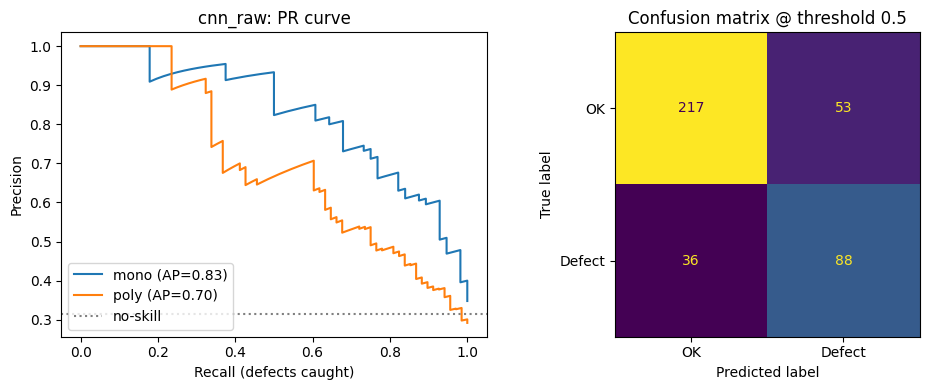

In [22]:

# CNN model experiment on raw image
model_rawimg, model_history_rawimg, result_rawimg = run_cnn_experiment("cnn_raw", use_clahe=False)


Epoch 1/30
58/58 - 16s - 278ms/step - loss: 0.6368 - pr_auc: 0.5826 - precision: 0.4857 - recall: 0.6516 - val_loss: 0.7207 - val_pr_auc: 0.2684 - val_precision: 0.3147 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/30
58/58 - 4s - 75ms/step - loss: 0.5697 - pr_auc: 0.6561 - precision: 0.5377 - recall: 0.6951 - val_loss: 0.6390 - val_pr_auc: 0.2327 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
58/58 - 4s - 77ms/step - loss: 0.5623 - pr_auc: 0.6451 - precision: 0.5363 - recall: 0.7073 - val_loss: 0.6640 - val_pr_auc: 0.2393 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/30
58/58 - 4s - 76ms/step - loss: 0.5655 - pr_auc: 0.6491 - precision: 0.5326 - recall: 0.6969 - val_loss: 0.6403 - val_pr_auc: 0.2222 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 5/30
58/58 - 5s - 80ms/step - loss: 0.5607 - pr_auc: 0.6462 - precision: 0.5240 - recall: 0.7230 - val_loss: 0.6673 - va

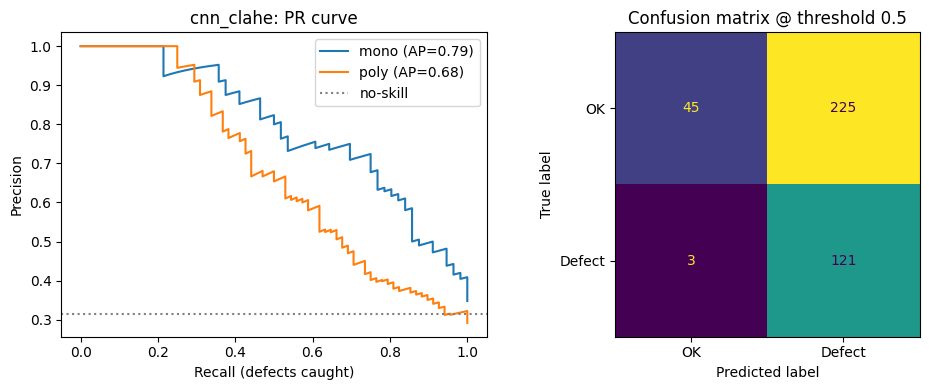

In [23]:
# CNN model experiment on OpenCV preprocessed image
model_clahe, model_history_clahe, result_clahe  = run_cnn_experiment("cnn_clahe", use_clahe=True)

# 6. Visualise model accuracy and loss
## 6.1 On raw image

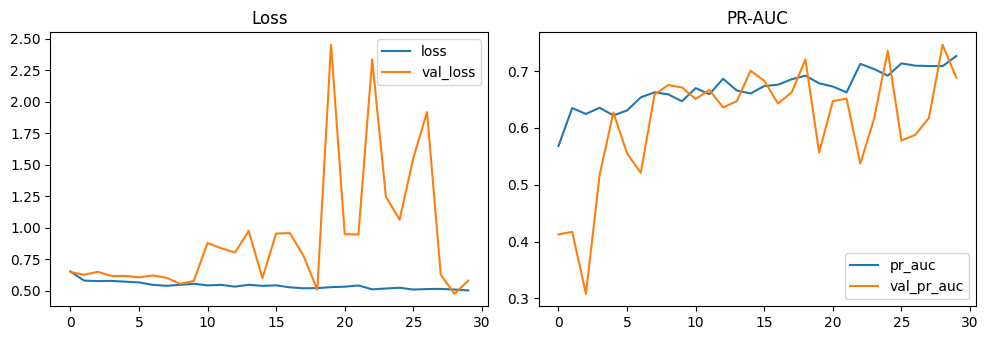

In [24]:
# plot accuracy vs loss metrics
plot_metrics(model_rawimg, model_history_rawimg)

## 6.2 On Open CV preprocessed image

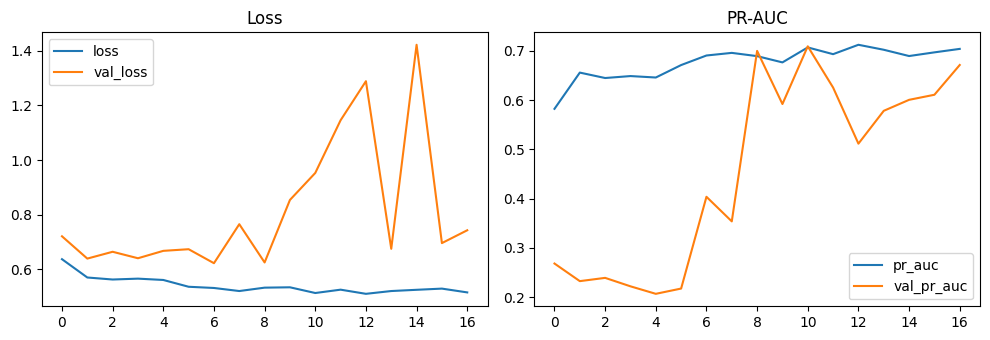

In [25]:
plot_metrics(model_clahe, model_history_clahe)

# 7. Evaluate model performance


## 7.1 On raw validation dataset

In [26]:
# Display model evaluating result

display(result_rawimg)

,model,group,n,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,cnn_raw,all,394,0.747,0.836,0.710,0.624,36,53
1,cnn_raw,mono,161,0.827,0.885,0.750,0.737,14,15
2,cnn_raw,poly,233,0.697,0.806,0.676,0.548,22,38


## 7.2 On Open CV preprocessed image

In [27]:
# Display model evaluating result

display(result_clahe)

,model,group,n,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,cnn_clahe,all,394,0.710,0.799,0.976,0.350,3,225
1,cnn_clahe,mono,161,0.793,0.853,1.000,0.400,0,84
2,cnn_clahe,poly,233,0.680,0.767,0.956,0.316,3,141


# 8. Save evaluation reuslt

In [29]:
# display overall comparison
res_cnn = pd.concat([result_rawimg, result_clahe])
display(res_cnn[res_cnn.group == "all"])

res_cnn.to_csv("outputs/eval_cnn.csv", index=False)
print("Saved outputs/eval_cnn.csv")

,model,group,n,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,cnn_raw,all,394,0.747,0.836,0.710,0.624,36,53
0,cnn_clahe,all,394,0.710,0.799,0.976,0.350,3,225


Saved outputs/eval_cnn.csv
